## Exercice 1

In [21]:
using Random: randn!
using Statistics

"""
Compute one simulation of the BS model with J time steps over [0,T]

# Arguments
- `path` an array of size J + 1, containing a simulation of the model on output
- `G`: an array of size J filled with normal random variables.
"""
function bsAsset!(path::Array{Float64}, sigma, r, T, spot, J::Int, G::Array)
    @assert length(path) == J + 1
    dt = T / J
    sqrt_dt = sqrt(dt)
    path[1] = spot
    for i in eachindex(path[1:end - 1])
        path[i + 1] = path[i] * exp((r - sigma * sigma / 2) * dt + sigma * sqrt_dt * G[i])
    end
end

"""
Compute the discrete time barrier payoff

#Arguments
- `path::Array`: an array with size J+1 containing a single simulation of the BS model
"""
function maxPayoff(path::Array{Float64}, strike)
    return max(maximum(path) - strike * path[end], 0)
end

function crudeMC(sigma, r, T, spot, J, strike, nSamples)
    price = 0.
    stdDev = 0.
    G = zeros(J)
    path = zeros(J + 1)
    for i=1:nSamples
        randn!(G)
        bsAsset!(path, sigma, r, T, spot, J, G)
        p = maxPayoff(path, strike) *exp(-r * T)
        price += p
        stdDev += p * p
    end
    price /= nSamples
    stdDev = stdDev / nSamples - price * price
    stdDev = sqrt(stdDev / nSamples)
    return price, 1.96 * stdDev
end


"""
Antithetic Monte Carlo

# Arguments
- `nSamples` is the number of the corresponding crude Monte Carlo method. In practice, we will only sample (nSamples / 2) random vectors.
"""
function antiMC(sigma, r, T, spot, J, strike, nSamples)
    price = 0.
    stdDev = 0.
    G = zeros(J)
    path = zeros(J + 1)
    nSamples_2 = nSamples // 2
    for i=1:nSamples_2
        randn!(G)
        bsAsset!(path, sigma, r, T, spot, J, G)
        p_plus = maxPayoff(path, strike) * exp(-r * T)
        bsAsset!(path, sigma, r, T, spot, J, -G)
        p_minus = maxPayoff(path, strike) * exp(-r * T)
        p = 0.5 * (p_plus + p_minus)
        price += p
        stdDev += p * p
    end
    price /= nSamples_2
    stdDev = stdDev / nSamples_2 - price * price
    stdDev = sqrt(stdDev / nSamples_2)
    return price, 1.96 * stdDev
end

function adaptiveControlMC(sigma, r, T, spot, J, strike, nSamples)
    price = 0.
    stdDev = 0.
    G = [randn(J) for i=1:nSamples]
    paths = [zeros(J + 1) for i=1:nSamples]
    bsAsset!.(paths, sigma, r, T, spot, J, G)
    payoffs = zeros(nSamples)
    @. payoffs = maxPayoff(paths, strike) * exp(-r * T)
    controls = [S[end] - spot * exp(r *T) for S in paths]
    lambdaStar = mean(controls .* payoffs) / var(controls)
    cashFlowsWithControl = (payoffs - lambdaStar * controls)
    price = mean(cashFlowsWithControl)
    stdDev = sqrt((mean(cashFlowsWithControl .* cashFlowsWithControl) - price * price) / nSamples)
    return price, 1.96 * stdDev, lambdaStar
end


adaptiveControlMC (generic function with 1 method)

In [22]:
spot = 100
K = 1.2
r = 0.02
sigma = 0.25
T = 2
nTimeSteps = 24
nSamples = 50000

println("Crude Monte Carlo estimator: ", crudeMC(sigma, r, T, spot, nTimeSteps, K, nSamples))
println("Antithetic Monte Carlo estimator: ", antiMC(sigma, r, T, spot, nTimeSteps, K, nSamples))
println("Antithetic Monte Carlo estimator: ", adaptiveControlMC(sigma, r, T, spot, nTimeSteps, K, nSamples))

Crude Monte Carlo estimator: (11.51938279885127, 0.13136857232673216)
Antithetic Monte Carlo estimator: (11.459640784389855, 0.09211713903214913)
Antithetic Monte Carlo estimator: (11.545030268493225, 0.10180758832651514, -0.2516308580127811)


## Exercice 2

In [23]:
function callPayoff(S, K)
    return max(S - K, 0.)
end

function bsMaturity(spot, sigma, r, T, G::Float64, theta)
    return spot * exp((r - sigma * sigma / 2) * T + sigma * sqrt(T) * (G + theta))
end

function computeTheta(spot, r, sigma, T, K, nSamples, gamma, beta)
    alpha = 1
    theta = zeros(nSamples)
    theta[1] = 0.
    for i=2:nSamples
        G = randn()
        ST = bsMaturity(spot, sigma, r, T, G, theta[i-1])
        proposal = theta[i - 1] - gamma / (i + 500) ^ beta * callPayoff(ST, K)^2 * (theta[i-1] - G) * exp(theta[i-1]^2 / 2 - theta[i-1] * G)
        if proposal^2 < log(alpha + 1)
            theta[i] = proposal
        else
            theta[i] = 0.
            alpha += 1
        end
    end
    return theta
end

computeTheta (generic function with 1 method)

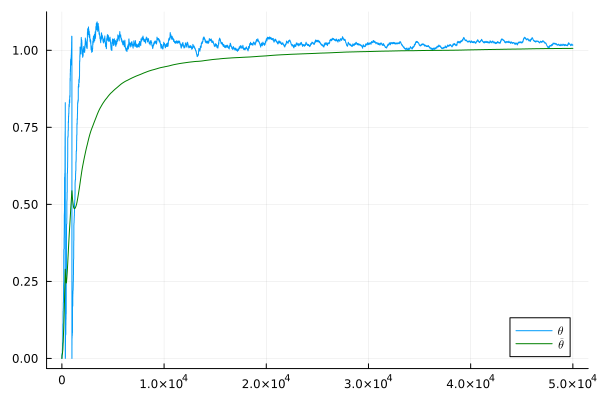

In [43]:
spot = 100
r = 0.03
sigma = 0.2
T = 2
K = 120
theta = computeTheta(spot, r, sigma, T, K, 50000, 0.001, 0.75)
barTheta = cumsum(theta) ./ (1:length(theta))

using Plots
using LaTeXStrings
plot(theta, label=L"\theta")
plot!(barTheta, color="green", label=L"\bar \theta")

In [47]:
function mcis(spot, sigma, r, T, K, nSamples, theta)
    price = 0.
    stdDev = 0.
    for i=1:nSamples
        G = randn()
        ST = bsMaturity(spot, sigma, r, T, G, theta)
        p = exp(-r * T) * callPayoff(ST, K) * exp(-theta * G - theta^2 / 2)
        price += p
        stdDev += p * p
    end
    price /= nSamples
    stdDev = sqrt(stdDev / nSamples - price^2)
    ciHalfWidth = 1.96 * stdDev / sqrt(nSamples)
    return (price, ciHalfWidth)
end

price, ci = mcis(spot, sigma, r, T, K, 500000, theta[end])
println("Monte Carlo with theta: ", price, " ± ", ci)
price, ci = mcis(spot, sigma, r, T, K, 500000, barTheta[end])
println("Monte Carlo with bar theta: ", price, " ± ", ci)
price, ci= mcis(spot, sigma, r, T, K, 500000, 0)
println("Crude Monte Carlo: ", price, " ± ", ci)

Monte Carlo with theta: 6.550563797411896 ± 0.014685826349961887
Monte Carlo with bar theta: 6.565252043206476 ± 0.014803471989307398
Crude Monte Carlo: 6.581526764348723 ± 0.043005575326424385
